In [21]:
import RocketSim
import numpy as np
import matplotlib.pyplot as plt

In [14]:
sim = RocketSim.RocketSim()
controls = RocketSim.Controls()

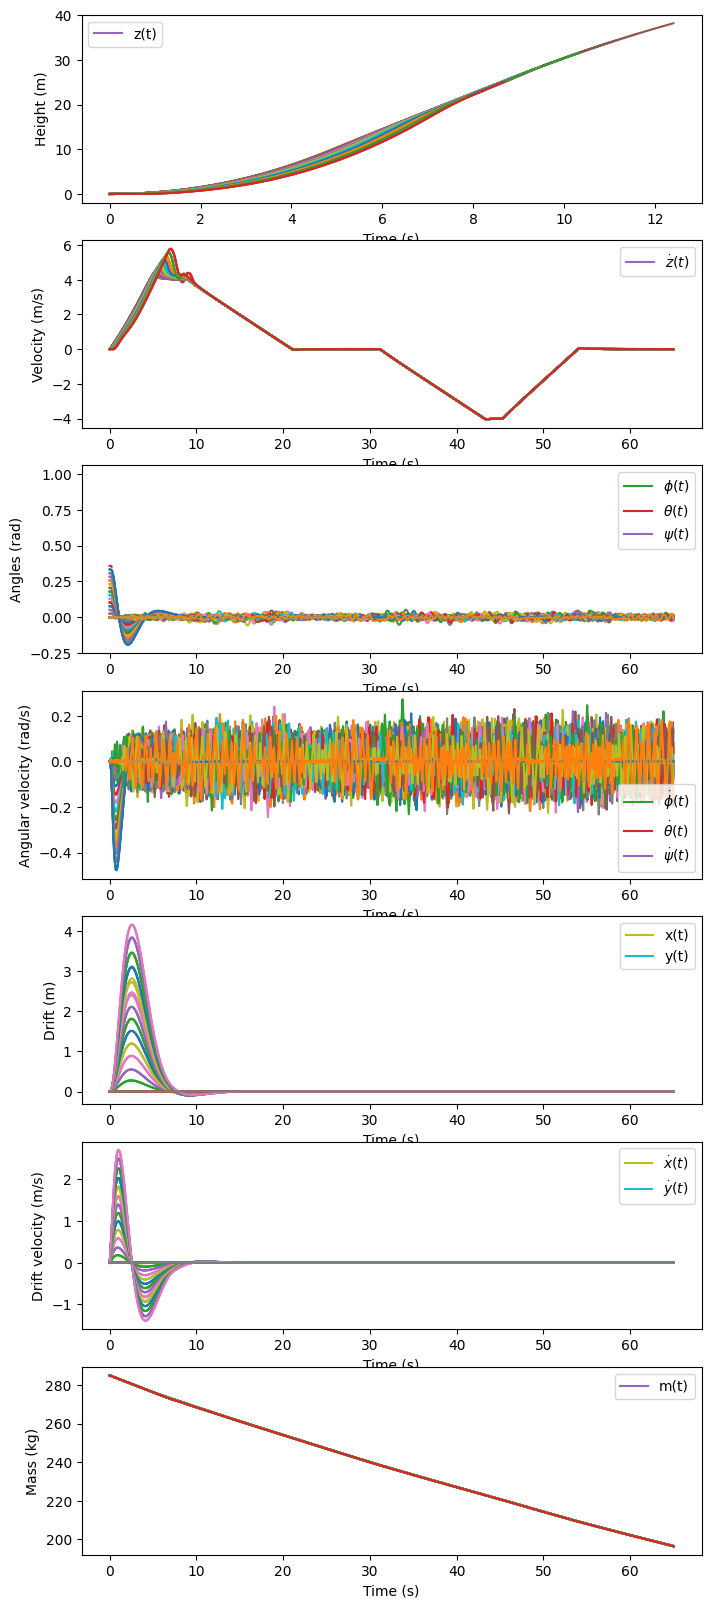

0.358974358974359


In [15]:
theta_failure = 0
for theta0 in np.linspace(0,1,40):
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                    0,0,0,
                                                                    0,theta0,0,
                                                                    0,0,0, 285])
    if sim.timestamps_cache[-1][-1] != 65:
        theta_failure = theta0
        break
#sim.plot([sim.timestamps_cache[-1]], [sim.states_cache[-1]], ["", "", "", "", "", ""], True)
sim.plot_cache(interval=(0,10))
print(theta_failure)

In [16]:
print([float(round(sim.timestamps_cache[i][-1], 2)) for i in range(len(sim.timestamps_cache))])

[65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 0.23, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 65.0, 0.0]


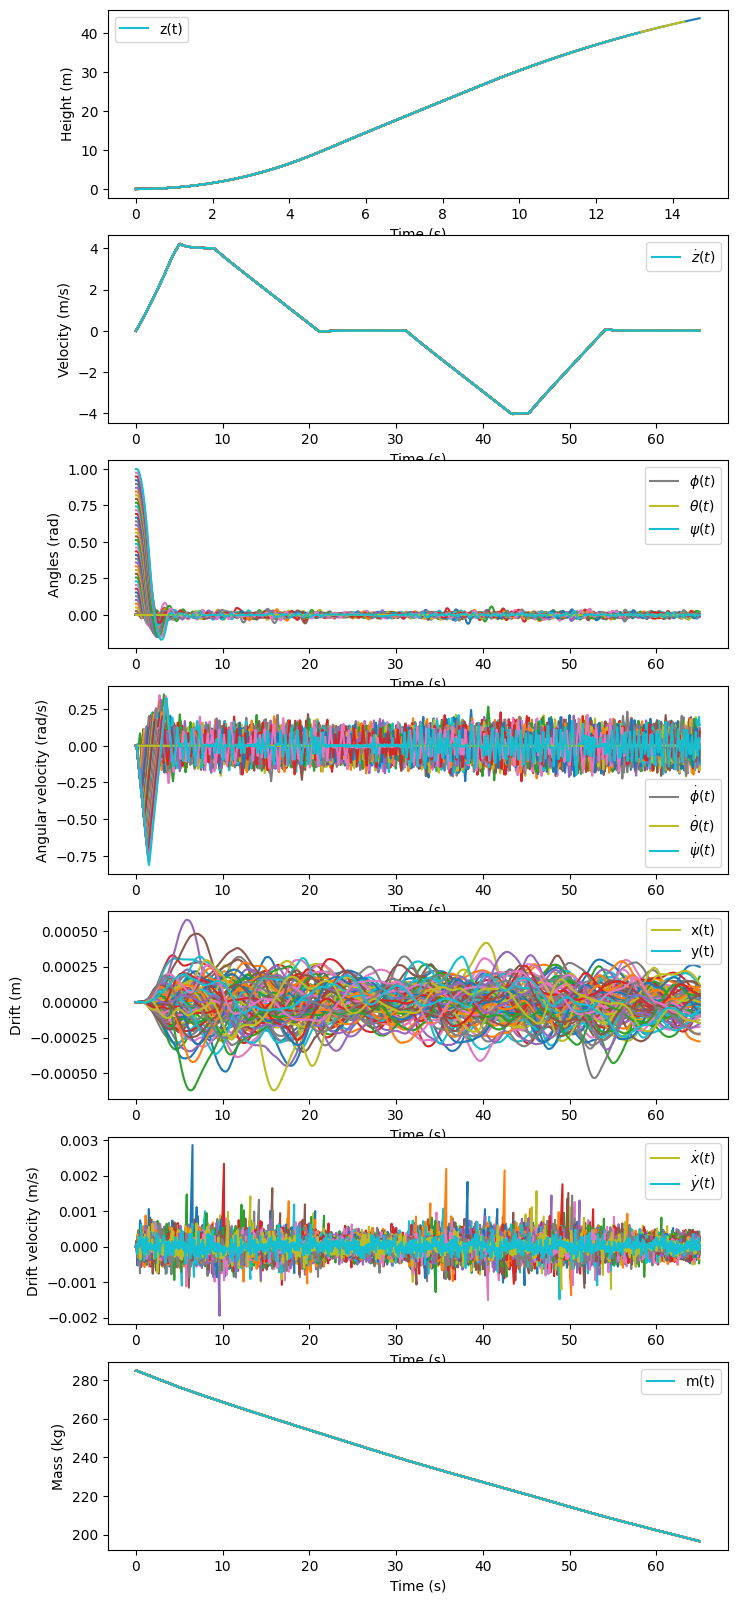

0


In [19]:
psi_failure = 0
for psi0 in np.linspace(0,1,40):
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                    0,0,0,
                                                                    0,0,psi0,
                                                                    0,0,0, 285])
    if sim.timestamps_cache[-1][-1] != 65:
        psi_failure = psi0
        break
#sim.plot([sim.timestamps_cache[-1]], [sim.states_cache[-1]], ["", "", "", "", "", ""], True)
sim.plot_cache(interval=(0,10))
print(psi_failure)

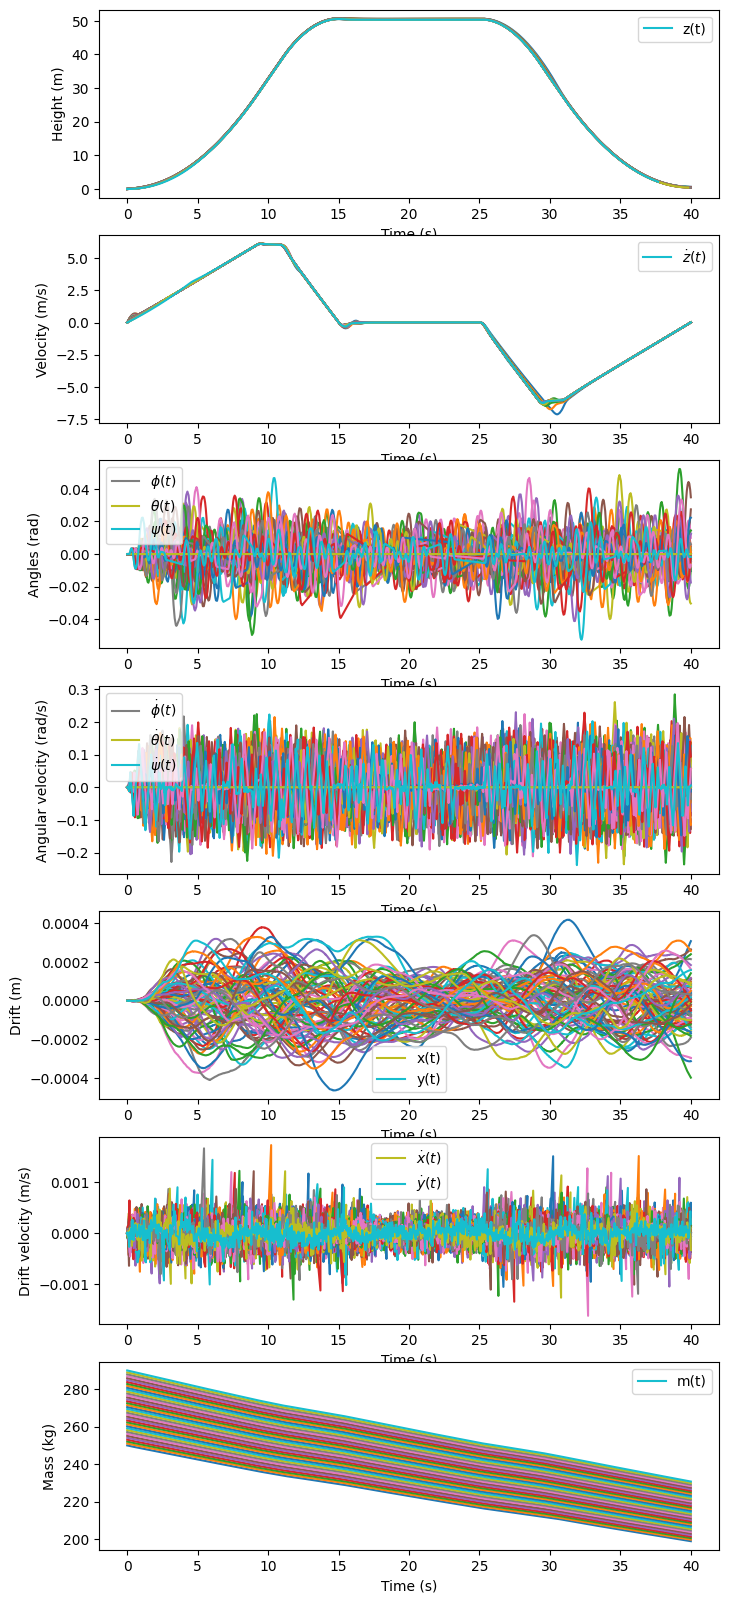

In [46]:
sim.clear_cache()
delta_m = []
mass_range = np.linspace(250,290,40)
for m in mass_range:
    T, P_max, m0, m_dot, dNoz, t_final, l, r, Tau0 = [3000,0.4,m,1.75, 0.7, 40, 2.5, 0.2, 3.23]
    H, V, Ti, Th, Tf, Z, Q, R, control_frequency = [50, 6, 15, 10, 40, 0.654, np.diag([0.1,350,0.1,320,20,50]), np.diag([2000,1536]),15]
    sim.set_params(T, P_max, m0, m_dot, dNoz, t_final, l, r, Tau0)
    controls.set_params(H, V, Ti, Th, Tf, Z, Q, R, control_frequency, sim)
    sim.with_control_algo(controls.LQR_control_algo).solve(State0 = [0,0,0,
                                                                    0,0,0,
                                                                    0,0,0,
                                                                    0,0,0, m])
    delta_m.append(m-sim.states_cache[-1][12][-1])
sim.plot_cache()

In [47]:
print([float(round(sim.states_cache[i][2][-1], 2)) for i in range(len(sim.states_cache))])
print(np.round(mass_range))
print(np.round(delta_m))

[0.63, 0.63, 0.62, 0.62, 0.61, 0.61, 0.6, 0.59, 0.59, 0.59, 0.57, 0.57, 0.56, 0.56, 0.55, 0.54, 0.55, 0.53, 0.53, 0.52, 0.51, 0.51, 0.5, 0.5, 0.49, 0.48, 0.48, 0.47, 0.47, 0.46, 0.45, 0.45, 0.44, 0.44, 0.43, 0.42, 0.42, 0.41, 0.41, 0.4]
[250. 251. 252. 253. 254. 255. 256. 257. 258. 259. 260. 261. 262. 263.
 264. 265. 266. 267. 268. 269. 271. 272. 273. 274. 275. 276. 277. 278.
 279. 280. 281. 282. 283. 284. 285. 286. 287. 288. 289. 290.]
[51. 51. 52. 52. 52. 52. 52. 53. 53. 53. 53. 53. 54. 54. 54. 54. 54. 55.
 55. 55. 55. 56. 56. 56. 56. 56. 57. 57. 57. 57. 57. 58. 58. 58. 58. 58.
 59. 59. 59. 59.]


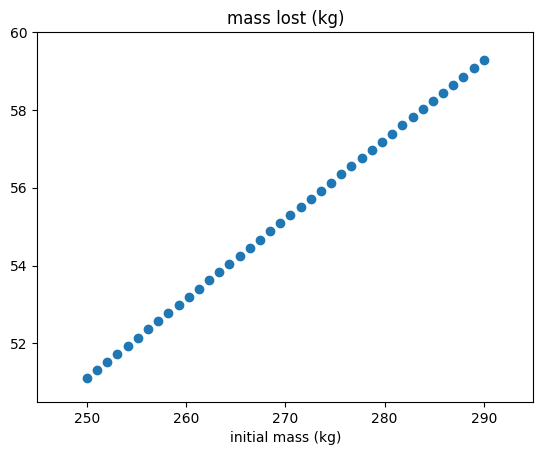

In [55]:
plt.scatter(mass_range, delta_m)
plt.ylim((50.5,60))
plt.xlim((245,295))
plt.title('mass lost (kg)')
plt.xlabel('initial mass (kg)')
#plt.plot(np.linspace(240,290,30), (np.linspace(240,290,30)-240)/5+49)
plt.show()